# Entregable 3 V2 — Análisis y predicción de ventas

## Objetivo
Integrar las tablas maestras y de ventas, validar la calidad de la información, realizar un análisis exploratorio y comparativo de ventas y construir modelos de predicción semanal. El flujo conserva trazabilidad desde la preparación de datos hasta la evaluación de modelos y el pronóstico futuro.

> **Nota de reproducibilidad:** las rutas de carga apuntan al equipo local del autor. Para ejecutar el notebook en otro entorno deben actualizarse las rutas de `DIM_CATEGORY.csv`, `DIM_SEGMENT.csv`, `DIM_PRODUCT.csv` y `FACT_SALES.csv`.


In [1]:
#Carga de archivo
import pandas as pd
df_category = pd.read_csv(r"C:\Users\samdl\Downloads\DIM_CATEGORY.csv")
#Verificar los tipos de datos
print(df_category.dtypes)

ID_CATEGORY    int64
CATEGORY         str
dtype: object


In [2]:
#Cambiar tipo de dato
df_category['CATEGORY'] = df_category['CATEGORY'].astype('string')
print(df_category.dtypes)

ID_CATEGORY     int64
CATEGORY       string
dtype: object


In [3]:
df_category

,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


## 1. Integración de dimensiones
Se incorporan las tablas de categoría y segmento. Los tipos de datos de variables descriptivas se homologan a `string` para facilitar uniones, validaciones y operaciones de texto. Posteriormente se genera una llave concatenada con atributos de producto para relacionar la clasificación comercial con el catálogo de materiales.


In [4]:
# Carga de segundo archivo
df_segment = pd.read_csv(r"C:\Users\samdl\Downloads\DIM_SEGMENT.csv")
print(df_segment.dtypes)

CATEGORY    int64
ATTR1         str
ATTR2         str
ATTR3         str
FORMAT        str
SEGMENT       str
dtype: object


In [5]:
df_segment['ATTR1'] = df_segment['ATTR1'].astype('string')
df_segment['ATTR2'] = df_segment['ATTR2'].astype('string')
df_segment['ATTR3'] = df_segment['ATTR3'].astype('string')
df_segment['FORMAT'] = df_segment['FORMAT'].astype('string')
df_segment['SEGMENT'] = df_segment['SEGMENT'].astype('string')
print(df_segment.dtypes)

CATEGORY     int64
ATTR1       string
ATTR2       string
ATTR3       string
FORMAT      string
SEGMENT     string
dtype: object


In [6]:
df_segment

,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH
1,1,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH
2,1,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH
3,1,CLORO,CLORO,MULTIUSOS,GEL,BLEACH
4,1,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH
5,1,CLORO,CLORO,NO DEFINIDO,LIQUIDO,BLEACH
6,1,CLORO,CLORO,NO DEFINIDO,POLVO,BLEACH
7,1,CLORO,CLORO,OTR. TIPOS,LIQUIDO,BLEACH
8,1,CLORO,CLORO,OTR. TIPOS,POLVO,BLEACH
9,1,CLORO,CLORO,ROPA BEBE,LIQUIDO,BLEACH


In [7]:
#Cambio del nombre de la columna CATEGORY
df_segment.rename(columns = {'CATEGORY': 'ID_CATEGORY'}, inplace = 'True')
#Unión de tablas Category y Segment
df_new_segment = pd.merge(df_category, df_segment, on = 'ID_CATEGORY', how = 'inner')
df_new_segment

C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\2856446217.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_segment.rename(columns = {'CATEGORY': 'ID_CATEGORY'}, inplace = 'True')


,ID_CATEGORY,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH
1,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH
2,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH
3,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,MULTIUSOS,GEL,BLEACH
4,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH
5,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,NO DEFINIDO,LIQUIDO,BLEACH
6,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,NO DEFINIDO,POLVO,BLEACH
7,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,OTR. TIPOS,LIQUIDO,BLEACH
8,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,OTR. TIPOS,POLVO,BLEACH
9,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,ROPA BEBE,LIQUIDO,BLEACH


In [8]:
# Obtener un concatenado de ATTR 1, 2 Y 3 y FORMAT

df_new_segment['Concatenado'] = (df_new_segment['ATTR1'] + df_new_segment['ATTR2'] 
                                 + df_new_segment['ATTR3'] + df_new_segment['FORMAT'])
df_new_segment

,ID_CATEGORY,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT,Concatenado
0,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH,CLOROCLOROBAMBINOLIQUIDO
1,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH,CLOROCLOROGERMICIDALIQUIDO
2,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH,CLOROCLOROMASCOTASLIQUIDO
3,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,MULTIUSOS,GEL,BLEACH,CLOROCLOROMULTIUSOSGEL
4,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH,CLOROCLOROMULTIUSOSLIQUIDO
5,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,NO DEFINIDO,LIQUIDO,BLEACH,CLOROCLORONO DEFINIDOLIQUIDO
6,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,NO DEFINIDO,POLVO,BLEACH,CLOROCLORONO DEFINIDOPOLVO
7,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,OTR. TIPOS,LIQUIDO,BLEACH,CLOROCLOROOTR. TIPOSLIQUIDO
8,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,OTR. TIPOS,POLVO,BLEACH,CLOROCLOROOTR. TIPOSPOLVO
9,1,FABRIC TREATMENT and SANIT\r\n,CLORO,CLORO,ROPA BEBE,LIQUIDO,BLEACH,CLOROCLOROROPA BEBELIQUIDO


In [9]:
#Ver si hay valores duplicados
df_new_segment["Concatenado"].duplicated().any()

np.False_

## 2. Preparación del catálogo de productos
Se carga `DIM_PRODUCT`, se normalizan tipos de datos y se revisan claves faltantes. Los dos productos sin `ITEM` reciben una clave explícita para evitar perderlos durante las uniones. También se eliminan ceros a la izquierda y se valida la unicidad de la clave de producto.


In [10]:
# Carga de tabla DIM_PRODUCT
df_product = pd.read_csv(r"C:\Users\samdl\Downloads\DIM_PRODUCT.csv", encoding = 'latin1')
print(df_product.dtypes)

MANUFACTURER          str
BRAND                 str
ITEM                  str
ITEM_DESCRIPTION      str
CATEGORY            int64
FORMAT                str
ATTR1                 str
ATTR2                 str
ATTR3                 str
dtype: object


In [11]:
df_product['MANUFACTURER'] = df_product['MANUFACTURER'].astype('string')
df_product['BRAND'] = df_product['BRAND'].astype('string')
df_product['ITEM_DESCRIPTION'] = df_product['ITEM_DESCRIPTION'].astype('string')
df_product['FORMAT'] = df_product['FORMAT'].astype('string')
df_product['ATTR1'] = df_product['ATTR1'].astype('string')
df_product['ATTR2'] = df_product['ATTR2'].astype('string')
df_product['ATTR3'] = df_product['ATTR3'].astype('string')
df_product['ITEM'] = df_product['ITEM'].astype('string')
print(df_product.dtypes)

MANUFACTURER        string
BRAND               string
ITEM                string
ITEM_DESCRIPTION    string
CATEGORY             int64
FORMAT              string
ATTR1               string
ATTR2               string
ATTR3               string
dtype: object


In [12]:
df_product

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
502,INDS. ALEN,CLORALEX,<NA>,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,<NA>,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


In [13]:
# Identificar valores que tienen NA en ITEM
df_product[df_product['ITEM'].isna()]

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
502,INDS. ALEN,CLORALEX,<NA>,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,<NA>,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


In [14]:
# Agregar un ITEM a los que no tienen
df_product.loc[df_product['ITEM_DESCRIPTION'] == 'CLORALEX EL RENDIDOR BOT PLAST 2LT', 'ITEM'] = 'CLORERBP2'
df_product.loc[df_product['ITEM_DESCRIPTION'] == 'CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L', 'ITEM'] = 'CLORMBDG10'
df_product

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
502,INDS. ALEN,CLORALEX,CLORERBP2,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,CLORMBDG10,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


In [15]:
#Eliminar ceros a la izquierda
df_product['ITEM'] = df_product['ITEM'].str.lstrip('0')
df_product

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,75000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,75000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,75000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,75000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,75000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
502,INDS. ALEN,CLORALEX,CLORERBP2,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,CLORMBDG10,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


In [16]:
#Ver si hay valores duplicados
df_product["ITEM"].duplicated().any()

np.False_

In [17]:
df_product['Concatenado'] = (df_product['ATTR1'] + df_product['ATTR2'] 
                                 + df_product['ATTR3'] + df_product['FORMAT'])
df_product

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,Concatenado
0,INDS. ALEN,CLORALEX,75000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
1,INDS. ALEN,CLORALEX,75000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
2,INDS. ALEN,CLORALEX,75000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
3,INDS. ALEN,CLORALEX,75000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
4,INDS. ALEN,CLORALEX,75000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
...,...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSALIQUIDO
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
502,INDS. ALEN,CLORALEX,CLORERBP2,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO
503,CLOROX,CLOROX,CLORMBDG10,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS,CLOROCLOROMASCOTASLIQUIDO


### Enriquecimiento del catálogo
El catálogo de productos se cruza con la clasificación de categoría/segmento mediante la llave concatenada. El resultado (`df_materials`) reúne atributos de producto y clasificación comercial en una sola tabla maestra.


In [18]:
# Traer al df_product info del df_new_segment
df_materials = df_product.merge(
    df_new_segment[["Concatenado", "CATEGORY", "SEGMENT"]], on = "Concatenado", how = "left")
df_materials

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY_x,FORMAT,ATTR1,ATTR2,ATTR3,Concatenado,CATEGORY_y,SEGMENT
0,INDS. ALEN,CLORALEX,75000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
1,INDS. ALEN,CLORALEX,75000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
2,INDS. ALEN,CLORALEX,75000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
3,INDS. ALEN,CLORALEX,75000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
4,INDS. ALEN,CLORALEX,75000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
...,...,...,...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSALIQUIDO,FABRIC TREATMENT and SANIT\r\n,LIQUID & GEL
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
502,INDS. ALEN,CLORALEX,CLORERBP2,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
503,CLOROX,CLOROX,CLORMBDG10,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS,CLOROCLOROMASCOTASLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH


In [19]:
df_materials.rename(columns = {'CATEGORY_x': 'ID_CATEGORY'}, inplace = 'True')
df_materials.rename(columns = {'CATEGORY_y': 'CATEGORY'}, inplace = 'True')
df_materials

C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\1152411753.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_materials.rename(columns = {'CATEGORY_x': 'ID_CATEGORY'}, inplace = 'True')
C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\1152411753.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_materials.rename(columns = {'CATEGORY_y': 'CATEGORY'}, inplace = 'True')


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,ID_CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,Concatenado,CATEGORY,SEGMENT
0,INDS. ALEN,CLORALEX,75000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
1,INDS. ALEN,CLORALEX,75000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
2,INDS. ALEN,CLORALEX,75000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
3,INDS. ALEN,CLORALEX,75000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
4,INDS. ALEN,CLORALEX,75000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
...,...,...,...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSALIQUIDO,FABRIC TREATMENT and SANIT\r\n,LIQUID & GEL
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
502,INDS. ALEN,CLORALEX,CLORERBP2,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
503,CLOROX,CLOROX,CLORMBDG10,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS,CLOROCLOROMASCOTASLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH


## 3. Preparación e integración de ventas
Se carga la tabla de hechos `FACT_SALES`. La variable `WEEK` se separa en número de semana y año; la clave `ITEM_CODE` se renombra como `ITEM` para homologarla con el catálogo de materiales. Finalmente se realiza un `left merge` para conservar todos los registros de ventas, incluso aquellos sin correspondencia en el maestro de producto.


In [20]:
# Carga del último archivo
df_sales = pd.read_csv(r"C:\Users\samdl\Downloads\FACT_SALES.csv")
print(df_sales.dtypes)

WEEK                               str
ITEM_CODE                          str
TOTAL_UNIT_SALES               float64
TOTAL_VALUE_SALES              float64
TOTAL_UNIT_AVG_WEEKLY_SALES    float64
REGION                             str
dtype: object


In [21]:
df_sales['WEEK'] = df_sales['WEEK'].astype('string')
df_sales['ITEM_CODE'] = df_sales['ITEM_CODE'].astype('string')
df_sales['REGION'] = df_sales['REGION'].astype('string')
df_sales.rename(columns = {'ITEM_CODE': 'ITEM'}, inplace = 'True')
df_sales

C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\2861571815.py:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_sales.rename(columns = {'ITEM_CODE': 'ITEM'}, inplace = 'True')


,WEEK,ITEM,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5
...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO
121998,26-23,7501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO
121999,26-23,7501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO


In [22]:
df_sales[["No. WEEK", "YEAR"]] = df_sales["WEEK"].str.strip().str.split('-', expand = True)
df_sales

,WEEK,ITEM,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,No. WEEK,YEAR
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,34,22
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,34,22
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,34,22
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,34,22
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,34,22
...,...,...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,26,23
121998,26-23,7501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,26,23
121999,26-23,7501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,26,23
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,26,23


In [23]:
print(df_sales.dtypes)

WEEK                            string
ITEM                            string
TOTAL_UNIT_SALES               float64
TOTAL_VALUE_SALES              float64
TOTAL_UNIT_AVG_WEEKLY_SALES    float64
REGION                          string
No. WEEK                        string
YEAR                            string
dtype: object


In [24]:
print(df_materials.dtypes)

MANUFACTURER        string
BRAND               string
ITEM                string
ITEM_DESCRIPTION    string
ID_CATEGORY          int64
FORMAT              string
ATTR1               string
ATTR2               string
ATTR3               string
Concatenado         string
CATEGORY            string
SEGMENT             string
dtype: object


In [25]:
print(df_sales.columns)
print(df_materials.columns)

Index(['WEEK', 'ITEM', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES',
       'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION', 'No. WEEK', 'YEAR'],
      dtype='str')
Index(['MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'ID_CATEGORY',
       'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3', 'Concatenado', 'CATEGORY',
       'SEGMENT'],
      dtype='str')


In [26]:
df_sales

,WEEK,ITEM,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,No. WEEK,YEAR
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,34,22
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,34,22
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,34,22
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,34,22
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,34,22
...,...,...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,26,23
121998,26-23,7501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,26,23
121999,26-23,7501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,26,23
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,26,23


In [27]:
df_materials

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,ID_CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,Concatenado,CATEGORY,SEGMENT
0,INDS. ALEN,CLORALEX,75000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
1,INDS. ALEN,CLORALEX,75000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
2,INDS. ALEN,CLORALEX,75000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
3,INDS. ALEN,CLORALEX,75000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
4,INDS. ALEN,CLORALEX,75000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
...,...,...,...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSALIQUIDO,FABRIC TREATMENT and SANIT\r\n,LIQUID & GEL
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
502,INDS. ALEN,CLORALEX,CLORERBP2,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,CLOROCLORONO DEFINIDOLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH
503,CLOROX,CLOROX,CLORMBDG10,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS,CLOROCLOROMASCOTASLIQUIDO,FABRIC TREATMENT and SANIT\r\n,BLEACH


In [28]:
import pandas as pd
#Mostrar columnas
print("columnas de df_sales: ", df_sales.columns.tolist())
print("columnas de df_materials: ", df_materials.columns.tolist())
#Verificar si "ITEM" está en ambos Data Frames
print("¿'ITEM' en df_sales: ", "ITEM" in df_sales.columns)
print("¿'ITEM' en df_columns: ", "ITEM" in df_materials.columns)
#intentar el merge
try:
    df_general = df_sales.merge(df_materials, on="ITEM", how="left")
    print("Columnas después del merge:", df_general.columns.tolist())
    print("primeras filas del resultado:\n", df_general.head())
except KeyError as e:
    print("Error durante el merge:", e)


columnas de df_sales:  ['WEEK', 'ITEM', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION', 'No. WEEK', 'YEAR']
columnas de df_materials:  ['MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'ID_CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3', 'Concatenado', 'CATEGORY', 'SEGMENT']
¿'ITEM' en df_sales:  True
¿'ITEM' en df_columns:  True
Columnas después del merge: ['WEEK', 'ITEM', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION', 'No. WEEK', 'YEAR', 'MANUFACTURER', 'BRAND', 'ITEM_DESCRIPTION', 'ID_CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3', 'Concatenado', 'CATEGORY', 'SEGMENT']
primeras filas del resultado:
     WEEK              ITEM  TOTAL_UNIT_SALES  TOTAL_VALUE_SALES  \
0  34-22  7501058792808BP2             0.006              0.139   
1  34-22     7501058715883             0.487            116.519   
2  34-22     7702626213774             1.391             68.453   
3  34-22     7501058716422             0.022      

In [29]:
df_general

,WEEK,ITEM,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,No. WEEK,YEAR,MANUFACTURER,BRAND,ITEM_DESCRIPTION,ID_CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,Concatenado,CATEGORY,SEGMENT
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
121998,26-23,7501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,1.0,LIQUIDO,PRELAVADOR,FABRIC TREATMENT,ROSA,PRELAVADORFABRIC TREATMENTROSALIQUIDO,FABRIC TREATMENT and SANIT\r\n,PRETREAT
121999,26-23,7501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISH PODER O2 DOYPACK 120 GR 7501058753441,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,SAFE BLEACHFABRIC TREATMENTROSAPOLVO,FABRIC TREATMENT and SANIT\r\n,POWDER


In [30]:
df_general = df_general.drop(columns = ["Concatenado"])
df_general

,WEEK,ITEM,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,No. WEEK,YEAR,MANUFACTURER,BRAND,ITEM_DESCRIPTION,ID_CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,CATEGORY,SEGMENT
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,34,22,RECKITT,VANISH,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISHOXIACTIONROSABOTE900GR+MMCRYSTALWHITEDOY...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
121998,26-23,7501058757630,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,1.0,LIQUIDO,PRELAVADOR,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,PRETREAT
121999,26-23,7501058753441,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISH PODER O2 DOYPACK 120 GR 7501058753441,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO,26,23,RECKITT,VANISH,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,1.0,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,FABRIC TREATMENT and SANIT\r\n,POWDER


### Exportación de la base integrada
La base consolidada se exporta como `Entregable3.csv`. Esta tabla constituye la fuente principal del análisis exploratorio y del modelado posterior.


In [31]:
#Guardar archivo
df_general.to_csv('Entregable3.csv', index = False)
print("Done!")

Done!


## 4. Control de calidad y análisis exploratorio (EDA)
Antes de interpretar resultados se revisan dimensiones, tipos, valores nulos, correspondencia de productos y duplicados. Esta etapa permite documentar las limitaciones de calidad de datos y evita confundir problemas de integración con patrones reales de negocio.


In [32]:
print(df_general.shape)
print("\nCOLUMNAS:")
print(df_general.columns.tolist())

print("\nTIPOS:")
print(df_general.dtypes)

print("\nNULOS:")
print(df_general.isnull().sum().sort_values(ascending=False).head(20))

(122002, 18)

COLUMNAS:
['WEEK', 'ITEM', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION', 'No. WEEK', 'YEAR', 'MANUFACTURER', 'BRAND', 'ITEM_DESCRIPTION', 'ID_CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3', 'CATEGORY', 'SEGMENT']

TIPOS:
WEEK                            string
ITEM                            string
TOTAL_UNIT_SALES               float64
TOTAL_VALUE_SALES              float64
TOTAL_UNIT_AVG_WEEKLY_SALES    float64
REGION                          string
No. WEEK                        string
YEAR                            string
MANUFACTURER                    string
BRAND                           string
ITEM_DESCRIPTION                string
ID_CATEGORY                    float64
FORMAT                          string
ATTR1                           string
ATTR2                           string
ATTR3                           string
CATEGORY                        string
SEGMENT                         string
dtype: object

NULOS:
BRAND

In [ ]:

# 1. PREPARACIÓN PARA EL ANÁLISIS EXPLORATORIO (EDA)


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convertir variables temporales
df_general["YEAR"] = pd.to_numeric(
    df_general["YEAR"],
    errors="coerce"
)

df_general["No. WEEK"] = pd.to_numeric(
    df_general["No. WEEK"],
    errors="coerce"
)

# Convertir año de 2 dígitos a 4 dígitos
df_general["YEAR_FULL"] = 2000 + df_general["YEAR"]

# Crear una fecha aproximada a partir de año y semana
df_general["FECHA"] = pd.to_datetime(
    df_general["YEAR_FULL"].astype("Int64").astype(str)
    + "-W"
    + df_general["No. WEEK"].astype("Int64").astype(str)
    + "-1",
    format="%G-W%V-%u",
    errors="coerce"
)

print("Dimensiones:", df_general.shape)
print(
    "Periodo:",
    df_general["FECHA"].min(),
    "a",
    df_general["FECHA"].max()
)

print("\nRegistros sin correspondencia de producto:")
print(df_general["CATEGORY"].isna().sum())

print("\nPorcentaje:")
print(
    round(
        df_general["CATEGORY"].isna().mean() * 100,
        2
    ),
    "%"
)

Dimensiones: (122002, 20)
Periodo: 2022-01-03 00:00:00 a 2023-07-10 00:00:00

Registros sin correspondencia de producto:
8523

Porcentaje:
6.99 %


> **Corrección de versión V3.** Las salidas previas se han limpiado para impedir que se confundan con resultados recalculados. Ejecuta el notebook completo en orden (`Restart Kernel and Run All`) con los archivos fuente disponibles. Actualiza las diapositivas y gráficas únicamente con los resultados de esta nueva ejecución.

## Control de niveles de agregación: consolidado nacional y áreas

**Hallazgo de auditoría:** `TOTAL AUTOS SCANNING MEXICO` coincide prácticamente con la suma de `TOTAL AUTOS AREA 1` a `TOTAL AUTOS AREA 6` por semana. En la revisión de 80 semanas, las diferencias observadas estuvieron entre −0.043 y +0.017 unidades de valor. Son compatibles con redondeos; no equivalen a una coincidencia exacta en todas las fechas.

**Decisión:** conservar `df_general` íntegro para trazabilidad y métricas de calidad originales. Crear `df_analisis` con **solo las seis áreas**, evitando contar dos veces las ventas al agregar por semana, mes o año. La suma de áreas se utiliza como consolidado reconstruido; el total nacional original sirve como control independiente. Las métricas y los modelos posteriores se calculan sobre `df_analisis`.

**Alcance:** las métricas de calidad de la fuente completa (por ejemplo, 122,002 filas y 6.99 % sin correspondencia) **no son automáticamente las mismas** que las de `df_analisis`. La segmentación por marca y SKU depende de la cobertura del catálogo. No se han auditado otros posibles solapamientos dentro de cada área.

In [ ]:
# VALIDACIÓN DEL CONSOLIDADO NACIONAL Y BASE SIN DOBLE CONTEO

import numpy as np
import pandas as pd

REGION_NACIONAL = "TOTAL AUTOS SCANNING MEXICO"
REGIONES_AREA = [f"TOTAL AUTOS AREA {i}" for i in range(1, 7)]

regiones_presentes = set(df_general["REGION"].dropna().unique())
faltantes = set(REGIONES_AREA + [REGION_NACIONAL]) - regiones_presentes
if faltantes:
    raise ValueError(f"Faltan regiones necesarias para validar: {sorted(faltantes)}")

comparacion_niveles = (
    df_general.groupby(["FECHA", "REGION"])["TOTAL_VALUE_SALES"]
    .sum().unstack(fill_value=0)
)
comparacion_niveles["Suma_areas"] = comparacion_niveles[REGIONES_AREA].sum(axis=1)
comparacion_niveles["Diferencia"] = (
    comparacion_niveles[REGION_NACIONAL] - comparacion_niveles["Suma_areas"]
)
comparacion_niveles["Diferencia_relativa_pct"] = np.where(
    comparacion_niveles["Suma_areas"].ne(0),
    100 * comparacion_niveles["Diferencia"] / comparacion_niveles["Suma_areas"],
    np.nan
)

print("CONTROL DE AGREGACIÓN — SEMANAS:", len(comparacion_niveles))
print(comparacion_niveles[["Suma_areas", REGION_NACIONAL,
                            "Diferencia", "Diferencia_relativa_pct"]].describe().round(6))
print("Máxima diferencia absoluta:", comparacion_niveles["Diferencia"].abs().max())
print("Máxima diferencia relativa (%):",
      comparacion_niveles["Diferencia_relativa_pct"].abs().max())

# Comprobación de equivalencia relativa; tolerancia 0.001%.
# No se afirma igualdad exacta por registro.
if not (comparacion_niveles["Diferencia_relativa_pct"].abs() < 0.001).all():
    raise ValueError("La equivalencia nacional-áreas requiere revisión antes de continuar")

# Copia analítica: seis áreas; el total nacional NO se suma otra vez.
df_analisis = df_general.loc[df_general["REGION"].isin(REGIONES_AREA)].copy()
print("\nFilas originales:", len(df_general))
print("Filas analíticas (áreas 1–6):", len(df_analisis))
print("Filas sin categoría en base analítica:", df_analisis["CATEGORY"].isna().sum())
print("Porcentaje sin categoría en base analítica:",
      round(100 * df_analisis["CATEGORY"].isna().mean(), 2))
print("Regiones en base analítica:", sorted(df_analisis["REGION"].unique()))

# Control adicional de unidades: comprobar también si el consolidado nacional
# reproduce las unidades de las seis áreas, antes de usar este indicador.
comparacion_unidades = (
    df_general.groupby(["FECHA", "REGION"])["TOTAL_UNIT_SALES"]
    .sum().unstack(fill_value=0)
)
comparacion_unidades["Diferencia_unidades"] = (
    comparacion_unidades[REGION_NACIONAL] -
    comparacion_unidades[REGIONES_AREA].sum(axis=1)
)
print("Máxima diferencia absoluta en unidades:",
      comparacion_unidades["Diferencia_unidades"].abs().max())


CONTROL DE AGREGACIÓN — SEMANAS: 80
REGION    Suma_areas  TOTAL AUTOS SCANNING MEXICO  Diferencia  \
count      80.000000                    80.000000   80.000000   
mean    69017.882162                 69017.866500   -0.015663   
std      7439.652788                  7439.653631    0.010513   
min     58336.416000                 58336.390000   -0.043000   
25%     63597.717750                 63597.701000   -0.023000   
50%     67474.537000                 67474.530500   -0.017000   
75%     72289.436000                 72289.409000   -0.008000   
max     99891.779000                 99891.755000    0.017000   

REGION  Diferencia_relativa_pct  
count                 80.000000  
mean                  -0.000023  
std                    0.000016  
min                   -0.000067  
25%                   -0.000033  
50%                   -0.000024  
75%                   -0.000013  
max                    0.000028  
Máxima diferencia absoluta: 0.04299999999784632
Máxima diferencia relati

In [ ]:
# 3. VALIDACIÓN DE DUPLICADOS

duplicados = df_analisis.duplicated().sum()

print("Registros duplicados:", duplicados)
print(
    "Porcentaje:",
    round(duplicados / len(df_analisis) * 100, 2),
    "%"
)

Registros duplicados: 0
Porcentaje: 0.0 %


### Estadística descriptiva y distribución
Se resumen las principales variables cuantitativas. La diferencia entre media, mediana, máximos y desviaciones estándar anticipa una distribución fuertemente asimétrica, por lo que se complementa el análisis con histograma, boxplot, IQR y escala logarítmica.


In [ ]:
# RESUMEN ESTADÍSTICO DE VARIABLES DE VENTAS


df_analisis[
    [
        "TOTAL_UNIT_SALES",
        "TOTAL_VALUE_SALES",
        "TOTAL_UNIT_AVG_WEEKLY_SALES"
    ]
].describe()

,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
count,101012.000000,101012.000000,101012.000000
mean,1.939177,54.661135,9.938591
std,6.445394,150.263682,22.428377
min,0.000000,0.001000,0.042000
25%,0.056000,2.406000,2.297750
50%,0.298000,14.062000,3.962000
75%,1.132000,49.441500,8.677000
max,143.003000,3307.388000,794.000000


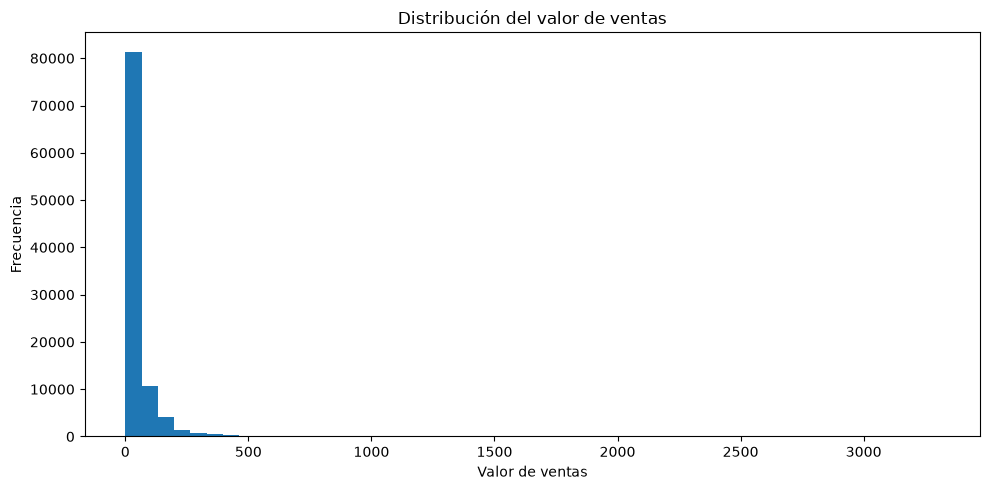

In [37]:
# Histograma
plt.figure(figsize=(10, 5))

plt.hist(
    df_analisis["TOTAL_VALUE_SALES"].dropna(),
    bins=50
)

plt.title("Distribución del valor de ventas")
plt.xlabel("Valor de ventas")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\3491757879.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


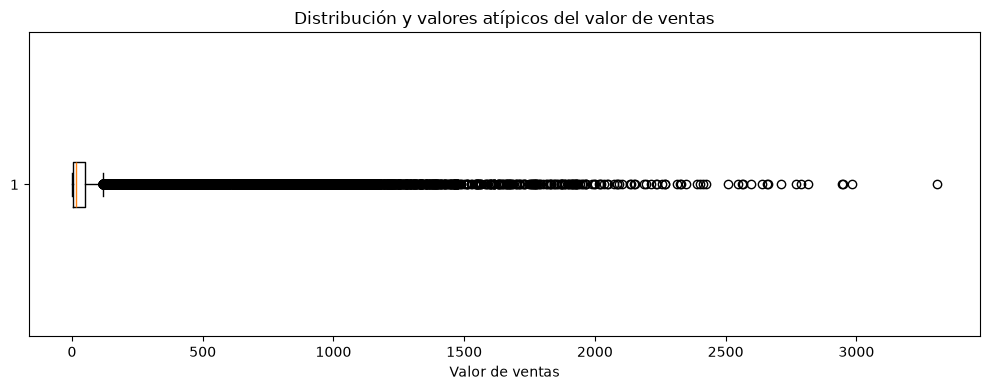

In [38]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df_analisis["TOTAL_VALUE_SALES"].dropna(),
    vert=False
)

plt.title("Distribución y valores atípicos del valor de ventas")
plt.xlabel("Valor de ventas")

plt.tight_layout()
plt.show()

### Identificación de valores atípicos
Se utiliza la regla de 1.5×IQR como criterio exploratorio. Los registros señalados como *outliers* no se eliminan automáticamente: en datos comerciales pueden representar compras reales de gran volumen. Por ello se revisan por región y marca antes de tomar decisiones de limpieza.


In [ ]:
# IDENTIFICACIÓN DE OUTLIERS MEDIANTE IQR

ventas = df_analisis["TOTAL_VALUE_SALES"].dropna()

Q1 = ventas.quantile(0.25)
Q3 = ventas.quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df_analisis[
    (df_analisis["TOTAL_VALUE_SALES"] < limite_inferior) |
    (df_analisis["TOTAL_VALUE_SALES"] > limite_superior)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Límite inferior:", round(limite_inferior, 2))
print("Límite superior:", round(limite_superior, 2))

print("\nPosibles outliers:", len(outliers))

print(
    "Porcentaje:",
    round(len(outliers) / len(df_analisis) * 100, 2),
    "%"
)

Q1: 2.41
Q3: 49.44
IQR: 47.04
Límite inferior: -68.15
Límite superior: 119.99

Posibles outliers: 10022
Porcentaje: 9.92 %


In [ ]:
# 7. ANÁLISIS DE LOS VALORES EXTREMOS

# Top 20 registros con mayor valor de ventas
columnas_mostrar = [
    "FECHA",
    "ITEM_DESCRIPTION",
    "BRAND",
    "REGION",
    "TOTAL_UNIT_SALES",
    "TOTAL_VALUE_SALES"
]

df_analisis[
    columnas_mostrar
].sort_values(
    "TOTAL_VALUE_SALES",
    ascending=False
).head(20)

,FECHA,ITEM_DESCRIPTION,BRAND,REGION,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
120850,2023-05-29,<NA>,<NA>,TOTAL AUTOS AREA 6,99.770,3307.388
81027,2023-05-29,<NA>,<NA>,TOTAL AUTOS AREA 2,135.953,2983.001
118497,2023-06-26,<NA>,<NA>,TOTAL AUTOS AREA 6,81.913,2947.336
69014,2022-05-30,<NA>,<NA>,TOTAL AUTOS AREA 2,134.124,2945.019
40666,2023-01-02,<NA>,<NA>,TOTAL AUTOS AREA 6,85.148,2813.144
44156,2023-02-27,<NA>,<NA>,TOTAL AUTOS AREA 6,73.803,2789.218
80008,2023-05-01,<NA>,<NA>,TOTAL AUTOS AREA 6,76.559,2767.812
115701,2023-07-03,<NA>,<NA>,TOTAL AUTOS AREA 6,74.897,2710.868
83854,2023-05-15,<NA>,<NA>,TOTAL AUTOS AREA 6,77.791,2661.864
77717,2023-04-24,<NA>,<NA>,TOTAL AUTOS AREA 6,72.539,2657.641


In [ ]:
# OUTLIERS POR REGIÓN

outliers_region = (
    outliers
    .groupby("REGION")
    .agg(
        Registros=("TOTAL_VALUE_SALES", "size"),
        Venta_total=("TOTAL_VALUE_SALES", "sum"),
        Venta_promedio=("TOTAL_VALUE_SALES", "mean"),
        Venta_maxima=("TOTAL_VALUE_SALES", "max")
    )
    .sort_values("Venta_total", ascending=False)
)

outliers_region

,Registros,Venta_total,Venta_promedio,Venta_maxima
REGION,,,,
TOTAL AUTOS AREA 2,2133,786869.220,368.902588,2983.001
TOTAL AUTOS AREA 5,2742,777452.853,283.534957,2315.010
TOTAL AUTOS AREA 6,1498,644932.060,430.528745,3307.388
TOTAL AUTOS AREA 3,1564,478083.572,305.680033,1909.032
TOTAL AUTOS AREA 1,963,414068.915,429.978105,1525.441
TOTAL AUTOS AREA 4,1122,353031.198,314.644561,1636.871


In [ ]:
# OUTLIERS POR MARCA


outliers_marca = (
    outliers
    .groupby("BRAND")
    .agg(
        Registros=("TOTAL_VALUE_SALES", "size"),
        Venta_total=("TOTAL_VALUE_SALES", "sum"),
        Venta_promedio=("TOTAL_VALUE_SALES", "mean"),
        Venta_maxima=("TOTAL_VALUE_SALES", "max")
    )
    .sort_values("Venta_total", ascending=False)
)

outliers_marca.head(15)

,Registros,Venta_total,Venta_promedio,Venta_maxima
BRAND,,,,
CLORALEX,3477,786057.872,226.073590,848.210
VANISH,2387,417508.844,174.909444,545.856
CLOROX,1294,329155.532,254.370581,944.495
BLANCATEL,581,282780.274,486.713036,2134.380
LOS PATITOS,172,47825.046,278.052593,460.978
OXI CLEAN,188,28329.889,150.690899,261.383
BANDERA,142,23412.622,164.877620,277.032
CLORTEX,50,7737.976,154.759520,217.574
DR.BECKMANN,50,6971.383,139.427660,207.068


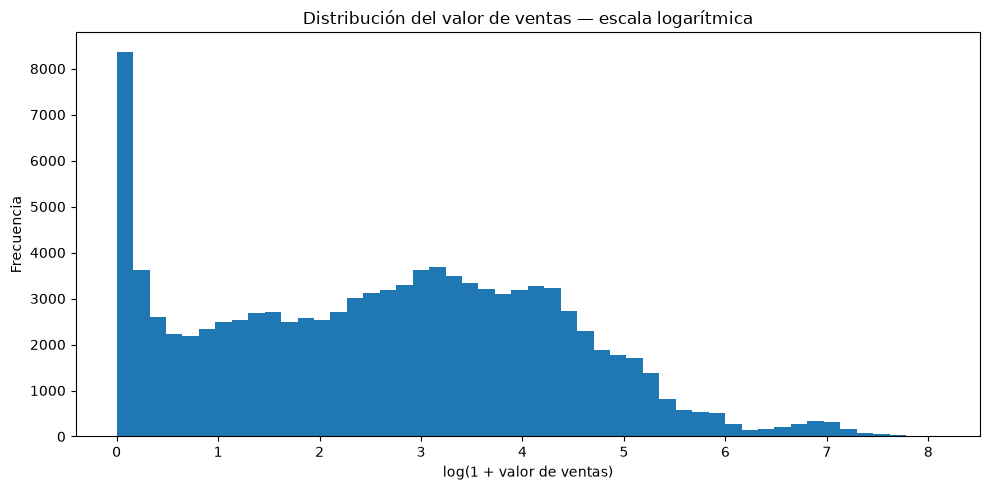

In [ ]:
# DISTRIBUCIÓN DE VENTAS EN ESCALA LOGARÍTMICA

plt.figure(figsize=(10, 5))

plt.hist(
    np.log1p(df_analisis["TOTAL_VALUE_SALES"]),
    bins=50
)

plt.title("Distribución del valor de ventas — escala logarítmica")
plt.xlabel("log(1 + valor de ventas)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## 5. Evolución temporal de las ventas
Las ventas se agregan a nivel semanal para reducir ruido transaccional y observar tendencia, picos y cambios de nivel. Se calcula una media móvil de cuatro semanas como referencia suavizada del comportamiento reciente.


In [ ]:
# 8. EVOLUCIÓN SEMANAL DE LAS VENTAS

ventas_semanales = (
    df_analisis
    .groupby("FECHA", as_index=False)
    .agg(
        Venta_total=("TOTAL_VALUE_SALES", "sum"),
        Unidades=("TOTAL_UNIT_SALES", "sum")
    )
    .sort_values("FECHA")
)

print("Semanas analizadas:", len(ventas_semanales))
print("Periodo:", ventas_semanales["FECHA"].min(), "a", ventas_semanales["FECHA"].max())

ventas_semanales.head()

Semanas analizadas: 80
Periodo: 2022-01-03 00:00:00 a 2023-07-10 00:00:00


,FECHA,Venta_total,Unidades
0,2022-01-03,75769.464,2830.917
1,2022-01-10,73498.512,2843.075
2,2022-01-17,62675.672,2422.438
3,2022-01-24,61972.820,2396.791
4,2022-01-31,64920.899,2510.636


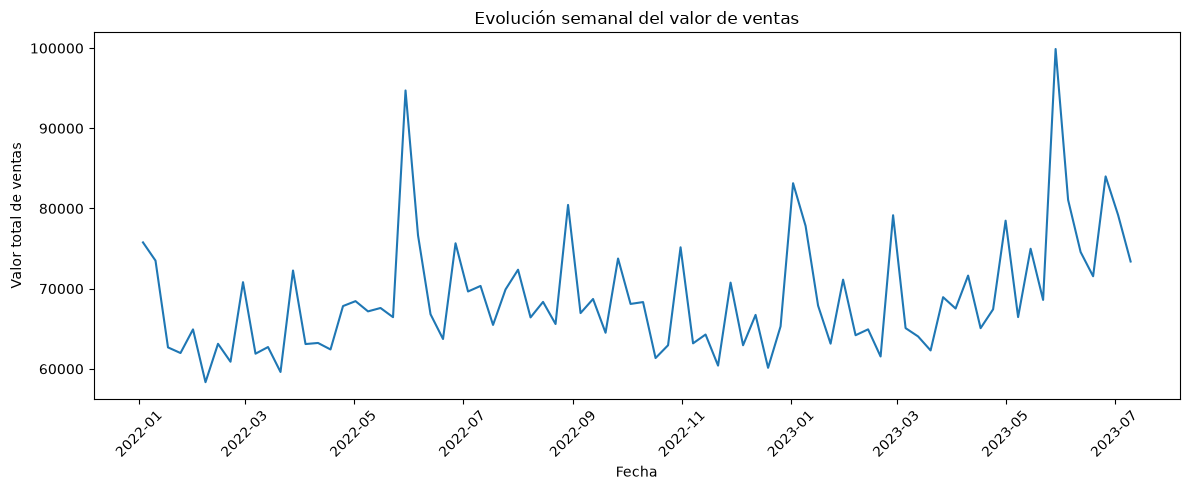

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(
    ventas_semanales["FECHA"],
    ventas_semanales["Venta_total"]
)

plt.title("Evolución semanal del valor de ventas")
plt.xlabel("Fecha")
plt.ylabel("Valor total de ventas")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

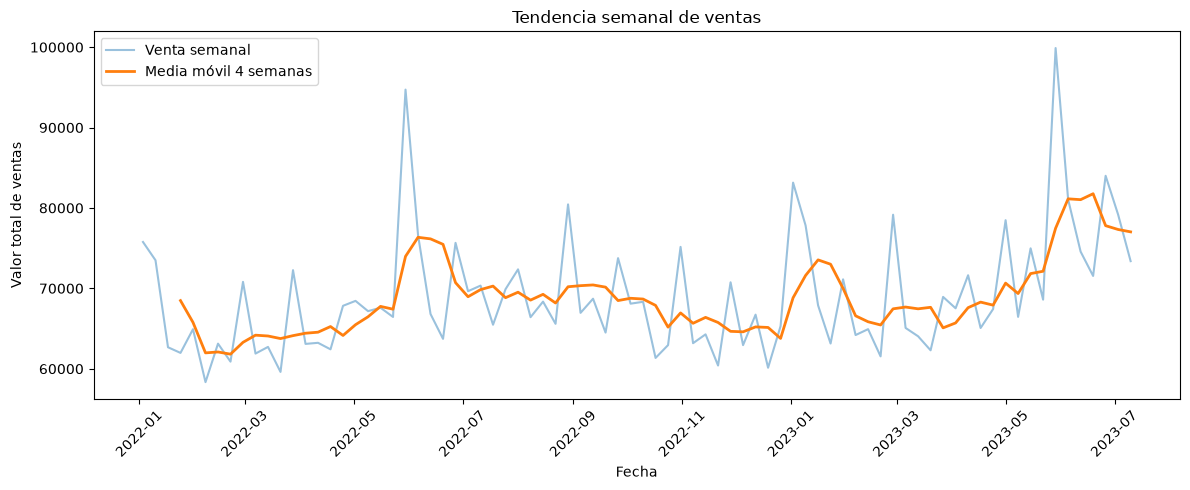

In [ ]:
# MEDIA MÓVIL DE 4 SEMANAS

ventas_semanales["Media_movil_4s"] = (
    ventas_semanales["Venta_total"]
    .rolling(window=4)
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    ventas_semanales["FECHA"],
    ventas_semanales["Venta_total"],
    alpha=0.45,
    label="Venta semanal"
)

plt.plot(
    ventas_semanales["FECHA"],
    ventas_semanales["Media_movil_4s"],
    linewidth=2,
    label="Media móvil 4 semanas"
)

plt.title("Tendencia semanal de ventas")
plt.xlabel("Fecha")
plt.ylabel("Valor total de ventas")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Comparación comparable 2022 vs. 2023
Dado que 2023 solo cuenta con información hasta julio, la comparación interanual se restringe a **enero–junio** en ambos años. Esto evita sesgos derivados de comparar un año completo contra un periodo parcial.


In [ ]:
# VENTAS MENSUALES

df_analisis["MES"] = df_analisis["FECHA"].dt.month

ventas_mensuales = (
    df_analisis
    .groupby(["YEAR_FULL", "MES"], as_index=False)
    ["TOTAL_VALUE_SALES"]
    .sum()
)

comparacion_mensual = ventas_mensuales.pivot(
    index="MES",
    columns="YEAR_FULL",
    values="TOTAL_VALUE_SALES"
)

comparacion_mensual

YEAR_FULL,2022,2023
MES,,
1,338837.367,363135.672
2,253155.440,269819.792
3,256481.919,260353.932
4,256568.289,271653.215
5,364365.997,388406.759
6,282841.138,311190.562
7,275368.464,152560.656
8,353166.094,NaN
9,273928.095,NaN


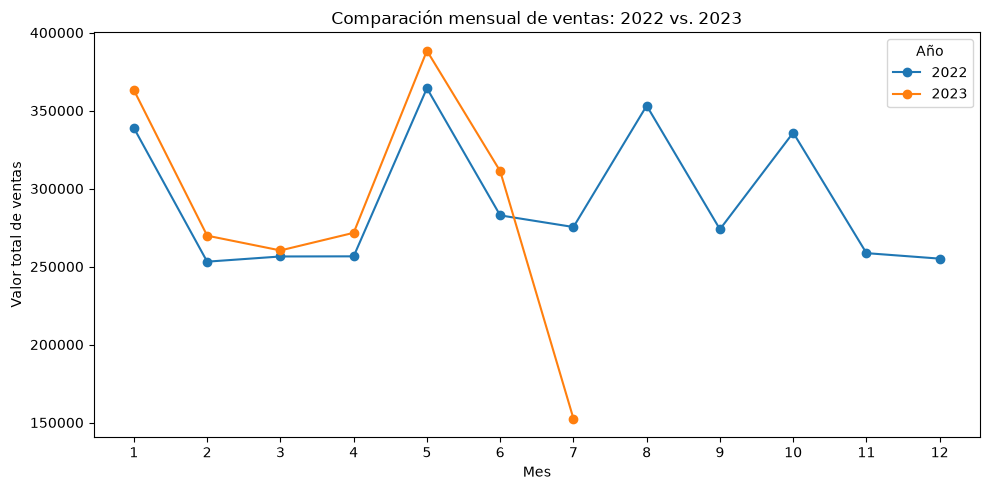

In [48]:
comparacion_mensual.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Comparación mensual de ventas: 2022 vs. 2023")
plt.xlabel("Mes")
plt.ylabel("Valor total de ventas")

plt.xticks(range(1, 13))
plt.legend(title="Año")
plt.tight_layout()
plt.show()

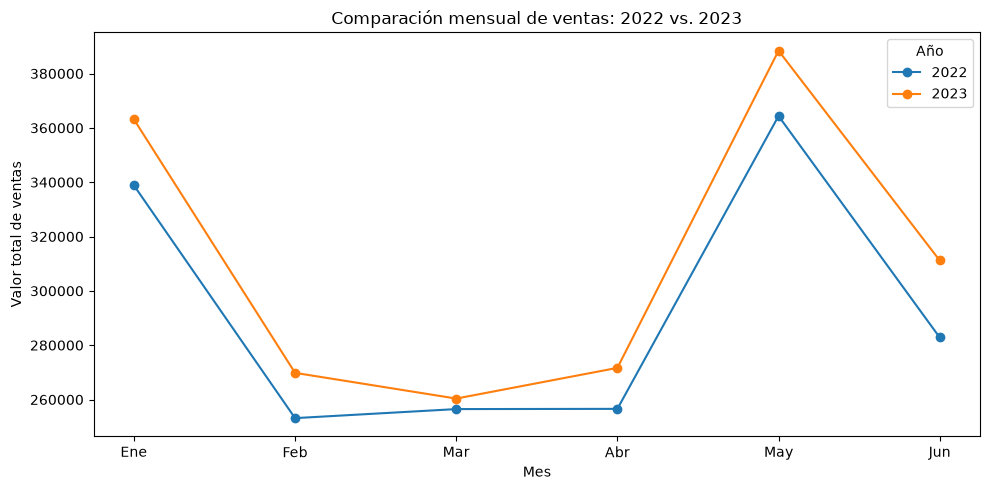

In [ ]:
# COMPARACIÓN JUSTA: ENERO-JUNIO 2022 VS 2023

comparacion_completa = comparacion_mensual.loc[1:6]

comparacion_completa.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Comparación mensual de ventas: 2022 vs. 2023")
plt.xlabel("Mes")
plt.ylabel("Valor total de ventas")

plt.xticks(
    range(1, 7),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun"]
)

plt.legend(title="Año")
plt.tight_layout()
plt.show()

In [50]:
venta_2022 = comparacion_completa[2022].sum()
venta_2023 = comparacion_completa[2023].sum()

crecimiento = ((venta_2023 / venta_2022) - 1) * 100

print(f"Ventas Ene-Jun 2022: {venta_2022:,.2f}")
print(f"Ventas Ene-Jun 2023: {venta_2023:,.2f}")
print(f"Crecimiento comparable: {crecimiento:.2f}%")

Ventas Ene-Jun 2022: 1,752,250.15
Ventas Ene-Jun 2023: 1,864,559.93
Crecimiento comparable: 6.41%


### Descomposición del crecimiento por región
Se calcula la variación absoluta, porcentual y la contribución al crecimiento. La contribución permite distinguir qué regiones explican el aumento agregado y no solo cuáles presentan una tasa porcentual alta.


In [ ]:
# 11. ANÁLISIS DE VENTAS POR REGIÓN

ventas_region = (
    df_analisis[
        (df_analisis["MES"] <= 6)
    ]
    .groupby(["YEAR_FULL", "REGION"])["TOTAL_VALUE_SALES"]
    .sum()
    .reset_index()
)

region_pivot = ventas_region.pivot(
    index="REGION",
    columns="YEAR_FULL",
    values="TOTAL_VALUE_SALES"
).fillna(0)

region_pivot["Variacion_abs"] = (
    region_pivot[2023] - region_pivot[2022]
)

region_pivot["Variacion_pct"] = (
    (region_pivot[2023] / region_pivot[2022]) - 1
) * 100

region_pivot = region_pivot.sort_values(
    "Variacion_abs",
    ascending=False
)

region_pivot

YEAR_FULL,2022,2023,Variacion_abs,Variacion_pct
REGION,,,,
TOTAL AUTOS AREA 2,375964.091,399112.508,23148.417,6.157082
TOTAL AUTOS AREA 6,309706.710,332275.735,22569.025,7.287225
TOTAL AUTOS AREA 5,372125.977,392908.635,20782.658,5.584845
TOTAL AUTOS AREA 3,254257.557,274343.227,20085.670,7.899734
TOTAL AUTOS AREA 1,222459.419,236977.992,14518.573,6.526392
TOTAL AUTOS AREA 4,217736.396,228941.835,11205.439,5.146333


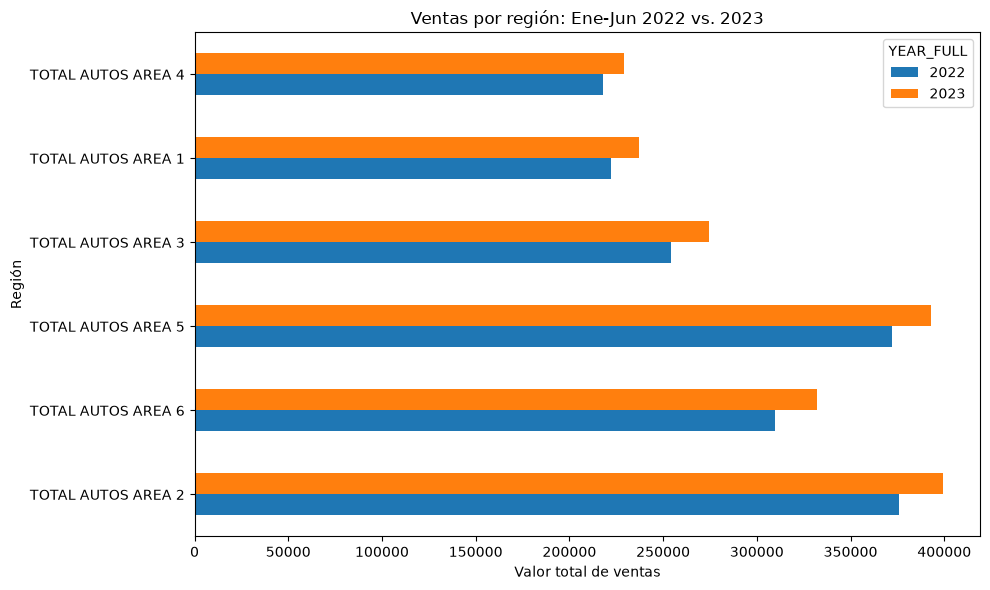

In [52]:
region_pivot[[2022, 2023]].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Ventas por región: Ene-Jun 2022 vs. 2023")
plt.xlabel("Valor total de ventas")
plt.ylabel("Región")
plt.tight_layout()
plt.show()

In [ ]:
# CONTRIBUCIÓN DE CADA REGIÓN AL CRECIMIENTO 2023

region_pivot["Crecimiento_abs"] = (
    region_pivot[2023] - region_pivot[2022]
)

crecimiento_total = region_pivot["Crecimiento_abs"].sum()

region_pivot["Contribucion_crecimiento_pct"] = (
    region_pivot["Crecimiento_abs"] / crecimiento_total
) * 100

resultado_region = region_pivot[
    [
        2022,
        2023,
        "Crecimiento_abs",
        "Variacion_pct",
        "Contribucion_crecimiento_pct"
    ]
].sort_values(
    "Crecimiento_abs",
    ascending=False
)

resultado_region.round(2)

YEAR_FULL,2022,2023,Crecimiento_abs,Variacion_pct,Contribucion_crecimiento_pct
REGION,,,,,
TOTAL AUTOS AREA 2,375964.09,399112.51,23148.42,6.16,20.61
TOTAL AUTOS AREA 6,309706.71,332275.74,22569.02,7.29,20.10
TOTAL AUTOS AREA 5,372125.98,392908.64,20782.66,5.58,18.50
TOTAL AUTOS AREA 3,254257.56,274343.23,20085.67,7.90,17.88
TOTAL AUTOS AREA 1,222459.42,236977.99,14518.57,6.53,12.93
TOTAL AUTOS AREA 4,217736.40,228941.84,11205.44,5.15,9.98


In [54]:
venta_2022 = comparacion_completa[2022].sum()
venta_2023 = comparacion_completa[2023].sum()

crecimiento = ((venta_2023 / venta_2022) - 1) * 100

print(f"Ventas Ene-Jun 2022: {venta_2022:,.2f}")
print(f"Ventas Ene-Jun 2023: {venta_2023:,.2f}")
print(f"Crecimiento: {crecimiento:.2f}%")

Ventas Ene-Jun 2022: 1,752,250.15
Ventas Ene-Jun 2023: 1,864,559.93
Crecimiento: 6.41%


### Descomposición del crecimiento por marca
El mismo enfoque se aplica a marcas para identificar impulsores y detractores. Una marca puede crecer mucho en porcentaje pero aportar poco al crecimiento total si su base de ventas es pequeña; por ello se prioriza la variación absoluta para la lectura ejecutiva.


In [ ]:
# 12. CRECIMIENTO DE VENTAS POR MARCA
#     Comparación Ene-Jun 2022 vs. Ene-Jun 2023

ventas_marca = (
    df_analisis[
        (df_analisis["MES"] <= 6) &
        (df_analisis["BRAND"].notna())
    ]
    .groupby(["YEAR_FULL", "BRAND"])["TOTAL_VALUE_SALES"]
    .sum()
    .reset_index()
)

marca_pivot = ventas_marca.pivot(
    index="BRAND",
    columns="YEAR_FULL",
    values="TOTAL_VALUE_SALES"
).fillna(0)

marca_pivot["Crecimiento_abs"] = (
    marca_pivot[2023] - marca_pivot[2022]
)

marca_pivot["Variacion_pct"] = np.where(
    marca_pivot[2022] > 0,
    ((marca_pivot[2023] / marca_pivot[2022]) - 1) * 100,
    np.nan
)

marca_pivot["Contribucion_crecimiento_pct"] = (
    marca_pivot["Crecimiento_abs"] /
    marca_pivot["Crecimiento_abs"].sum()
) * 100

marca_pivot = marca_pivot.sort_values(
    "Crecimiento_abs",
    ascending=False
)

marca_pivot.round(2)

YEAR_FULL,2022,2023,Crecimiento_abs,Variacion_pct,Contribucion_crecimiento_pct
BRAND,,,,,
VANISH,324262.00,379054.77,54792.77,16.90,87.93
CLOROX,212662.58,249515.24,36852.66,17.33,59.14
CLORALEX,384683.68,410744.38,26060.71,6.77,41.82
DR.BECKMANN,39304.35,52891.73,13587.38,34.57,21.80
OXI CLEAN,64048.74,74697.85,10649.11,16.63,17.09
CUELLOS PUNOS Y MANCHITAS,3107.86,3610.98,503.12,16.19,0.81
CLORTEX,5957.43,6123.81,166.38,2.79,0.27
IBERIA,1881.91,1897.09,15.18,0.81,0.02
PURO SOL,11.05,12.24,1.19,10.79,0.00


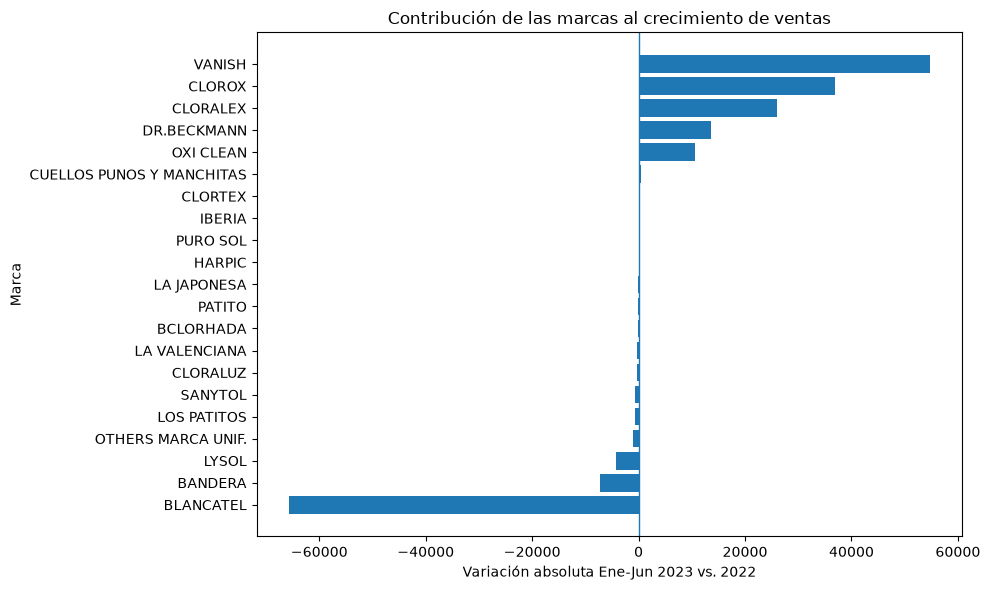

In [ ]:
# MARCAS QUE MÁS APORTARON / RESTARON AL CRECIMIENTO

impacto_marca = marca_pivot.sort_values(
    "Crecimiento_abs",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    impacto_marca.index,
    impacto_marca["Crecimiento_abs"]
)

plt.axvline(0, linewidth=1)

plt.title("Contribución de las marcas al crecimiento de ventas")
plt.xlabel("Variación absoluta Ene-Jun 2023 vs. 2022")
plt.ylabel("Marca")

plt.tight_layout()
plt.show()

### Análisis a nivel producto
Se identifican los SKU con mayor impacto positivo y negativo en la variación Ene–Jun 2023 vs. 2022. Esta vista permite traducir el resultado agregado a acciones comerciales concretas sobre portafolio.


In [ ]:
# 13. CRECIMIENTO DE VENTAS POR PRODUCTO
#     Ene-Jun 2022 vs. Ene-Jun 2023

ventas_producto = (
    df_analisis[
        (df_analisis["MES"] <= 6) &
        (df_analisis["ITEM_DESCRIPTION"].notna())
    ]
    .groupby(
        ["YEAR_FULL", "ITEM_DESCRIPTION"]
    )["TOTAL_VALUE_SALES"]
    .sum()
    .reset_index()
)

producto_pivot = ventas_producto.pivot(
    index="ITEM_DESCRIPTION",
    columns="YEAR_FULL",
    values="TOTAL_VALUE_SALES"
).fillna(0)

producto_pivot["Crecimiento_abs"] = (
    producto_pivot[2023] -
    producto_pivot[2022]
)

producto_pivot["Variacion_pct"] = np.where(
    producto_pivot[2022] > 0,
    ((producto_pivot[2023] /
      producto_pivot[2022]) - 1) * 100,
    np.nan
)

# Top productos que más impulsaron el crecimiento
top_crecimiento = (
    producto_pivot
    .sort_values("Crecimiento_abs", ascending=False)
    .head(10)
)

# Top productos que más restaron
top_caida = (
    producto_pivot
    .sort_values("Crecimiento_abs")
    .head(10)
)

print("TOP 10 PRODUCTOS QUE IMPULSARON EL CRECIMIENTO")
display(top_crecimiento.round(2))

print("\nTOP 10 PRODUCTOS QUE REDUJERON EL CRECIMIENTO")
display(top_caida.round(2))

TOP 10 PRODUCTOS QUE IMPULSARON EL CRECIMIENTO


YEAR_FULL,2022,2023,Crecimiento_abs,Variacion_pct
ITEM_DESCRIPTION,,,,
CLORALEX CLORO EN GEL BP 2000ML 7501025405106,15931.73,46253.28,30321.56,190.32
CLOROX REGULAR CONCENTRADO BOTPLAST.3800ML 7501071900143,56392.12,82705.24,26313.12,46.66
CLORALEX EL RENDIDOR BLANQ DESINF DEODORIZ CONCEN BP 1.65LT 7501025409104,0.00,13570.42,13570.42,NaN
VANISH ROSA QUITAMANCHAS GEL BOT 3.8 LT PROM ESP 7501058716767,14699.26,27076.91,12377.66,84.21
VANISH CRYSTAL WHITE QUITAMANCHAS GEL BOT 3.8 LT PROM ESP 7501058716798,7209.72,15864.52,8654.79,120.04
CLOROX ROPA COLOR Q.MANCHAS LIQ. BOT. 3.8LT NAL 7501071902109,13785.42,19811.05,6025.63,43.71
CLORALEX ULTRAGEL CLORO EN GEL CONCENTRADO 950ML 7501025405212,37895.53,43602.23,5706.70,15.06
CLORALEX CLORO EN GEL BOT 950ML 7501025405151,30391.54,35769.81,5378.27,17.70
OXI CLEAN QUITAMANCHAS VERSATIL SOBRE 110 GR 7501080900165,3064.03,8153.42,5089.39,166.10



TOP 10 PRODUCTOS QUE REDUJERON EL CRECIMIENTO


YEAR_FULL,2022,2023,Crecimiento_abs,Variacion_pct
ITEM_DESCRIPTION,,,,
BLANCATEL CONCENTRADO BOT PLAST 3750ML NAL 7501025402051,87193.08,54404.49,-32788.60,-37.60
CLORALEX GEL NO SALPICA DESINFECTANTE BP 1.65LT 7501025401948,27161.26,212.64,-26948.62,-99.22
BLANCATEL CONCENTRADO BOT PLAST 3750ML NAL 7501025401993,21748.70,442.92,-21305.78,-97.96
BLANCATEL LAVANDA LIQ BOT PLAST 3750ML NAL 7501025402242,16611.49,8323.30,-8288.19,-49.89
CLORALEX EL RENDIDOR CLORO LIQ DESINFECT C/G500ML BOT=3.75L 7501025412357,9645.93,1597.38,-8048.55,-83.44
VANISH BOT. 4000 ML. 7501058757791,20861.97,14937.40,-5924.57,-28.40
BANDERA CLORHADA BLANQUEADOR CONCENTRADO LIMON BOT 4LT 7501681100223,17023.76,11613.62,-5410.13,-31.78
CLORALEX ULTRAGEL CLORO GEL CONCENTRADO BOT 600 ML 7501025405090,41211.76,35939.75,-5272.01,-12.79
BANDERA CLORHADA CONCENTRADO BOT. PLAS 2000 ML NAL 7501681100773,6160.22,2411.36,-3748.86,-60.86


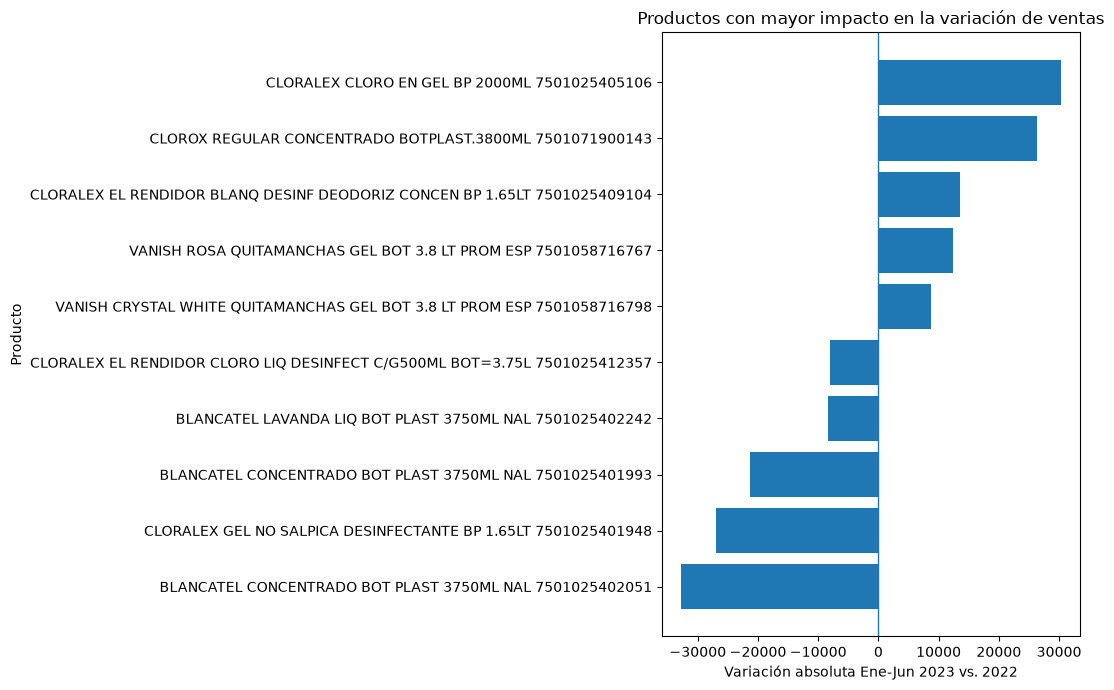

In [58]:
impacto_productos = pd.concat([
    top_caida.head(5),
    top_crecimiento.head(5)
]).sort_values("Crecimiento_abs")

plt.figure(figsize=(11, 7))

plt.barh(
    impacto_productos.index,
    impacto_productos["Crecimiento_abs"]
)

plt.axvline(0, linewidth=1)

plt.title(
    "Productos con mayor impacto en la variación de ventas"
)
plt.xlabel(
    "Variación absoluta Ene-Jun 2023 vs. 2022"
)
plt.ylabel("Producto")

plt.tight_layout()
plt.show()

## 7. Preparación del modelo predictivo
La serie semanal se transforma en un problema supervisado. Se generan variables temporales (`Mes`, `Semana`, `Tendencia`) y variables de memoria (`Lag_1`, `Lag_2`, `Lag_4`, media móvil de 4 semanas). Los primeros registros con rezagos incompletos se excluyen del modelado.


In [ ]:
# MACHINE LEARNING
# 1. CONSTRUCCIÓN DE LA SERIE SEMANAL

serie_ml = (
    df_analisis
    .groupby("FECHA", as_index=False)
    .agg(
        Ventas=("TOTAL_VALUE_SALES", "sum"),
        Unidades=("TOTAL_UNIT_SALES", "sum")
    )
    .sort_values("FECHA")
    .reset_index(drop=True)
)

print("Número de semanas:", len(serie_ml))
print("Periodo:", serie_ml["FECHA"].min(), "a", serie_ml["FECHA"].max())

serie_ml.head()

Número de semanas: 80
Periodo: 2022-01-03 00:00:00 a 2023-07-10 00:00:00


,FECHA,Ventas,Unidades
0,2022-01-03,75769.464,2830.917
1,2022-01-10,73498.512,2843.075
2,2022-01-17,62675.672,2422.438
3,2022-01-24,61972.820,2396.791
4,2022-01-31,64920.899,2510.636


In [ ]:
# 2. CREACIÓN DE VARIABLES TEMPORALES

serie_ml["Año"] = serie_ml["FECHA"].dt.year
serie_ml["Mes"] = serie_ml["FECHA"].dt.month
serie_ml["Semana"] = serie_ml["FECHA"].dt.isocalendar().week.astype(int)

# Tendencia temporal
serie_ml["Tendencia"] = np.arange(len(serie_ml))

# Ventas de semanas anteriores
serie_ml["Lag_1"] = serie_ml["Ventas"].shift(1)
serie_ml["Lag_2"] = serie_ml["Ventas"].shift(2)
serie_ml["Lag_4"] = serie_ml["Ventas"].shift(4)

# Promedio móvil usando SOLO información anterior
serie_ml["Media_4_sem"] = (
    serie_ml["Ventas"]
    .shift(1)
    .rolling(4)
    .mean()
)

serie_ml[
    [
        "FECHA",
        "Ventas",
        "Mes",
        "Semana",
        "Tendencia",
        "Lag_1",
        "Lag_2",
        "Lag_4",
        "Media_4_sem"
    ]
].head(10)

,FECHA,Ventas,Mes,Semana,Tendencia,Lag_1,Lag_2,Lag_4,Media_4_sem
0,2022-01-03,75769.464,1,1,0,NaN,NaN,NaN,NaN
1,2022-01-10,73498.512,1,2,1,75769.464,NaN,NaN,NaN
2,2022-01-17,62675.672,1,3,2,73498.512,75769.464,NaN,NaN
3,2022-01-24,61972.820,1,4,3,62675.672,73498.512,NaN,NaN
4,2022-01-31,64920.899,1,5,4,61972.820,62675.672,75769.464,68479.11700
5,2022-02-07,58336.416,2,6,5,64920.899,61972.820,73498.512,65766.97575
6,2022-02-14,63123.892,2,7,6,58336.416,64920.899,62675.672,61976.45175
7,2022-02-21,60886.459,2,8,7,63123.892,58336.416,61972.820,62088.50675
8,2022-02-28,70808.673,2,9,8,60886.459,63123.892,64920.899,61816.91650
9,2022-03-07,61890.075,3,10,9,70808.673,60886.459,58336.416,63288.86000


In [61]:
modelo_df = serie_ml.dropna().copy()

print("Observaciones disponibles para modelado:", len(modelo_df))

modelo_df[
    [
        "FECHA",
        "Ventas",
        "Mes",
        "Semana",
        "Tendencia",
        "Lag_1",
        "Lag_2",
        "Lag_4",
        "Media_4_sem"
    ]
].head()

Observaciones disponibles para modelado: 76


,FECHA,Ventas,Mes,Semana,Tendencia,Lag_1,Lag_2,Lag_4,Media_4_sem
4,2022-01-31,64920.899,1,5,4,61972.820,62675.672,75769.464,68479.11700
5,2022-02-07,58336.416,2,6,5,64920.899,61972.820,73498.512,65766.97575
6,2022-02-14,63123.892,2,7,6,58336.416,64920.899,62675.672,61976.45175
7,2022-02-21,60886.459,2,8,7,63123.892,58336.416,61972.820,62088.50675
8,2022-02-28,70808.673,2,9,8,60886.459,63123.892,64920.899,61816.91650


### División temporal entrenamiento/prueba
La separación se realiza de forma cronológica: 64 observaciones para entrenamiento y las últimas 12 semanas para prueba. **No se barajan los datos**, ya que hacerlo introduciría información futura en el entrenamiento y produciría una validación optimista.


### Validación temporal y alcance del pronóstico

Se conserva el corte cronológico de las últimas 12 semanas como prueba. Las variables rezagadas y la media móvil usan observaciones anteriores. **Atención:** en la validación de regresión se utilizan rezagos reales observados en el periodo de prueba (predicción a un paso con información histórica disponible); el pronóstico futuro de 12 semanas es **recursivo**, porque incorpora sus propias predicciones. Por ello, el RMSE del conjunto de prueba no constituye una garantía de precisión a 12 pasos. ARIMA se evalúa mediante un pronóstico multietapa desde el final del entrenamiento, lo que debe considerarse al comparar modelos.

In [ ]:
# 3. DIVISIÓN CRONOLÓGICA TRAIN / TEST

# Variables predictoras
features = [
    "Mes",
    "Semana",
    "Tendencia",
    "Lag_1",
    "Lag_2",
    "Lag_4",
    "Media_4_sem"
]

X = modelo_df[features]
y = modelo_df["Ventas"]

# Últimas 12 semanas como periodo de prueba
n_test = 12

X_train = X.iloc[:-n_test]
X_test  = X.iloc[-n_test:]

y_train = y.iloc[:-n_test]
y_test  = y.iloc[-n_test:]

fechas_train = modelo_df["FECHA"].iloc[:-n_test]
fechas_test  = modelo_df["FECHA"].iloc[-n_test:]

print("Observaciones entrenamiento:", len(X_train))
print("Observaciones prueba:", len(X_test))

print("\nPeriodo entrenamiento:")
print(fechas_train.min(), "a", fechas_train.max())

print("\nPeriodo prueba:")
print(fechas_test.min(), "a", fechas_test.max())

Observaciones entrenamiento: 64
Observaciones prueba: 12

Periodo entrenamiento:
2022-01-31 00:00:00 a 2023-04-17 00:00:00

Periodo prueba:
2023-04-24 00:00:00 a 2023-07-10 00:00:00


### Baseline
El baseline asume que la próxima semana será igual a la semana anterior. Es una referencia mínima indispensable: un modelo más complejo solo agrega valor si logra superar consistentemente esta regla simple.


In [ ]:
# 4. BASELINE — VENTA DE LA SEMANA ANTERIOR

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

pred_baseline = X_test["Lag_1"]

mae_baseline = mean_absolute_error(y_test, pred_baseline)
mse_baseline = mean_squared_error(y_test, pred_baseline)
rmse_baseline = np.sqrt(mse_baseline)

print("BASELINE")
print("-" * 30)
print(f"MAE:  {mae_baseline:,.2f}")
print(f"MSE:  {mse_baseline:,.2f}")
print(f"RMSE: {rmse_baseline:,.2f}")

BASELINE
------------------------------
MAE:  10,254.54
MSE:  165,222,652.11
RMSE: 12,853.90


### Regresión lineal múltiple
La regresión utiliza las variables temporales y rezagadas para estimar ventas semanales. Su desempeño se evalúa exclusivamente sobre las 12 semanas reservadas como prueba mediante MAE, MSE y RMSE.


In [ ]:
# 5. REGRESIÓN LINEAL MÚLTIPLE

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Crear y entrenar modelo
modelo_lr = LinearRegression()

modelo_lr.fit(X_train, y_train)

# Predicción sobre las 12 semanas de prueba
pred_lr = modelo_lr.predict(X_test)

# Métricas
mae_lr = mean_absolute_error(y_test, pred_lr)
mse_lr = mean_squared_error(y_test, pred_lr)
rmse_lr = np.sqrt(mse_lr)

print("REGRESIÓN LINEAL MÚLTIPLE")
print("-" * 35)

print(f"MAE:  {mae_lr:,.2f}")
print(f"MSE:  {mse_lr:,.2f}")
print(f"RMSE: {rmse_lr:,.2f}")

REGRESIÓN LINEAL MÚLTIPLE
-----------------------------------
MAE:  7,291.95
MSE:  95,753,755.35
RMSE: 9,785.38


In [ ]:
# 6. COMPARACIÓN BASELINE VS REGRESIÓN

comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión lineal múltiple"
    ],
    "MAE": [
        mae_baseline,
        mae_lr
    ],
    "MSE": [
        mse_baseline,
        mse_lr
    ],
    "RMSE": [
        rmse_baseline,
        rmse_lr
    ]
})

comparacion_modelos

,Modelo,MAE,MSE,RMSE
0,Baseline,10254.543917,1.652227e+08,12853.896378
1,Regresión lineal múltiple,7291.950567,9.575376e+07,9785.384783


In [ ]:
# 7. REAL VS PREDICCIÓN

resultado_lr = pd.DataFrame({
    "Fecha": fechas_test.values,
    "Real": y_test.values,
    "Prediccion_LR": pred_lr,
    "Baseline": pred_baseline.values
})

resultado_lr["Error_LR"] = (
    resultado_lr["Real"] -
    resultado_lr["Prediccion_LR"]
)

resultado_lr

,Fecha,Real,Prediccion_LR,Baseline,Error_LR
0,2023-04-24,67426.694,69830.149586,65071.650,-2403.455586
1,2023-05-01,78480.582,63237.072245,67426.694,15243.509755
2,2023-05-08,66455.942,71817.106561,78480.582,-5361.164561
3,2023-05-15,74980.511,66769.313497,66455.942,8211.197503
4,2023-05-22,68597.945,69380.134202,74980.511,-782.189202
5,2023-05-29,99891.779,75149.101176,68597.945,24742.677824
6,2023-06-05,81070.232,74630.912403,99891.779,6439.319597
7,2023-06-12,74571.565,73578.412913,81070.232,993.152087
8,2023-06-19,71546.082,63066.207603,74571.565,8479.874397
9,2023-06-26,84002.683,77665.593069,71546.082,6337.089931


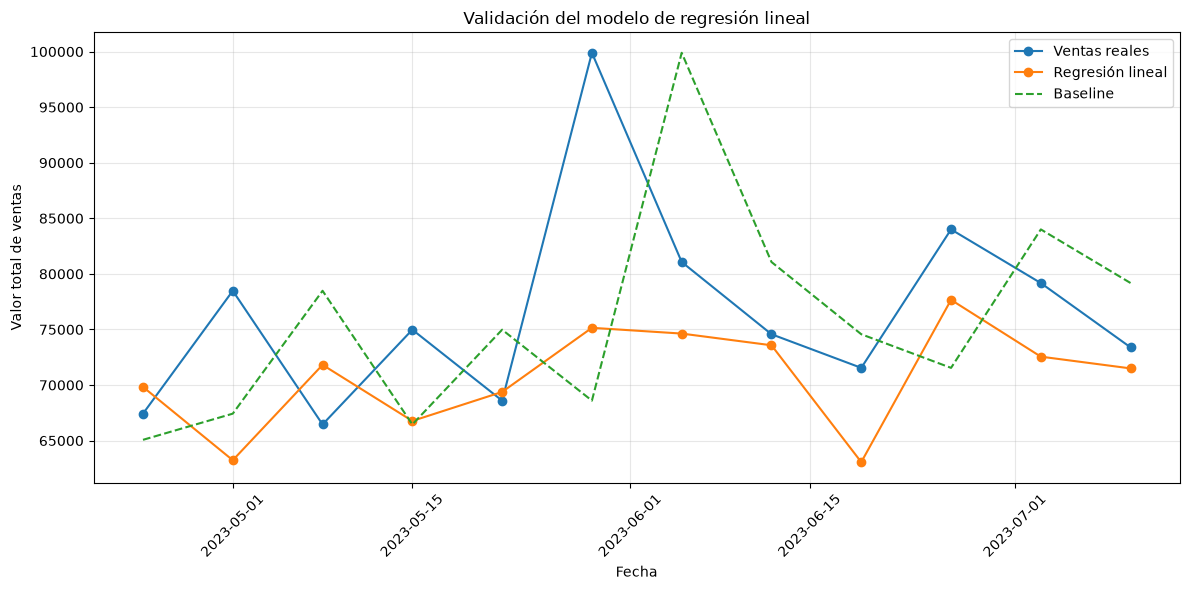

In [ ]:
# 8. GRÁFICO DE VALIDACIÓN

plt.figure(figsize=(12, 6))

plt.plot(
    resultado_lr["Fecha"],
    resultado_lr["Real"],
    marker="o",
    label="Ventas reales"
)

plt.plot(
    resultado_lr["Fecha"],
    resultado_lr["Prediccion_LR"],
    marker="o",
    label="Regresión lineal"
)

plt.plot(
    resultado_lr["Fecha"],
    resultado_lr["Baseline"],
    linestyle="--",
    label="Baseline"
)

plt.title("Validación del modelo de regresión lineal")
plt.xlabel("Fecha")
plt.ylabel("Valor total de ventas")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Modelado ARIMA y estacionariedad
Antes de ajustar ARIMA se evalúa estacionariedad con la prueba ADF. La serie original no es estacionaria (`p=0.7625`). La primera diferencia queda cerca del umbral de 5% (`p=0.0559`), mientras que la segunda diferencia sí resulta estacionaria (`p=0.0005`). ACF y PACF se utilizan como apoyo diagnóstico para proponer órdenes candidatos.


In [ ]:
# 9. PRUEBA DE ESTACIONARIEDAD — ADF

from statsmodels.tsa.stattools import adfuller

serie_ventas = (
    serie_ml
    .set_index("FECHA")["Ventas"]
    .sort_index()
)

resultado_adf = adfuller(serie_ventas)

print("PRUEBA ADF — SERIE ORIGINAL")
print("-" * 35)
print(f"ADF Statistic: {resultado_adf[0]:.4f}")
print(f"p-value:       {resultado_adf[1]:.4f}")

print("\nValores críticos:")

for clave, valor in resultado_adf[4].items():
    print(f"{clave}: {valor:.4f}")

PRUEBA ADF — SERIE ORIGINAL
-----------------------------------
ADF Statistic: -0.9743
p-value:       0.7625

Valores críticos:
1%: -3.5320
5%: -2.9058
10%: -2.5904


C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\2594768610.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie_ventas)


In [ ]:
# 10. ADF — PRIMERA DIFERENCIA
serie_diff = serie_ventas.diff().dropna()

resultado_adf_diff = adfuller(serie_diff)

print("PRUEBA ADF — PRIMERA DIFERENCIA")
print("-" * 40)
print(f"ADF Statistic: {resultado_adf_diff[0]:.4f}")
print(f"p-value:       {resultado_adf_diff[1]:.4f}")

print("\nValores críticos:")

for clave, valor in resultado_adf_diff[4].items():
    print(f"{clave}: {valor:.4f}")

PRUEBA ADF — PRIMERA DIFERENCIA
----------------------------------------
ADF Statistic: -2.8166
p-value:       0.0559

Valores críticos:
1%: -3.5336
5%: -2.9064
10%: -2.5907


C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\2170773388.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf_diff = adfuller(serie_diff)


<Figure size 1000x500 with 0 Axes>

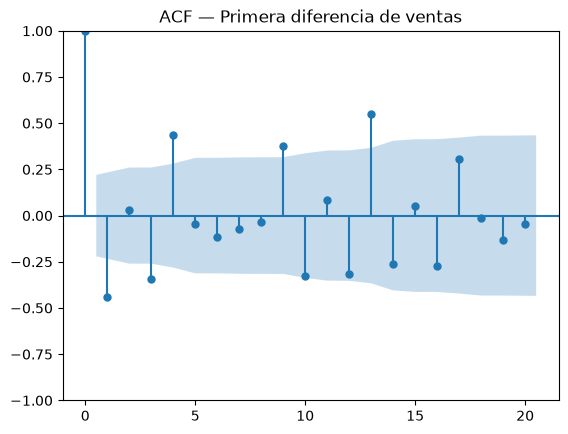

<Figure size 1000x500 with 0 Axes>

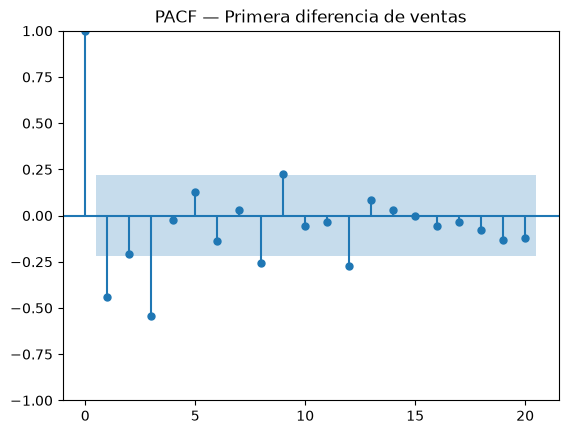

In [ ]:
# 11. ACF Y PACF DE LA PRIMERA DIFERENCIA

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plot_acf(
    serie_diff,
    lags=20,
    alpha=0.05
)
plt.title("ACF — Primera diferencia de ventas")
plt.show()

plt.figure(figsize=(10, 5))
plot_pacf(
    serie_diff,
    lags=20,
    alpha=0.05,
    method="ywm"
)
plt.title("PACF — Primera diferencia de ventas")
plt.show()

In [ ]:
# 12. ADF — SEGUNDA DIFERENCIA

serie_diff2 = serie_ventas.diff().diff().dropna()

resultado_adf_diff2 = adfuller(serie_diff2)

print("PRUEBA ADF — SEGUNDA DIFERENCIA")
print("-" * 40)

print(f"ADF Statistic: {resultado_adf_diff2[0]:.4f}")
print(f"p-value:       {resultado_adf_diff2[1]:.4f}")

print("\nValores críticos:")

for clave, valor in resultado_adf_diff2[4].items():
    print(f"{clave}: {valor:.4f}")

PRUEBA ADF — SEGUNDA DIFERENCIA
----------------------------------------
ADF Statistic: -4.2616
p-value:       0.0005

Valores críticos:
1%: -3.5336
5%: -2.9064
10%: -2.5907


C:\Users\samdl\AppData\Local\Temp\ipykernel_4500\3475871683.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf_diff2 = adfuller(serie_diff2)


### Comparación de órdenes ARIMA
Se prueban distintas combinaciones `(p,d,q)` y se comparan tanto criterios de ajuste (AIC/BIC) como métricas fuera de muestra. Para este trabajo se prioriza el error de predicción sobre el periodo de prueba. El mejor ARIMA por RMSE es **ARIMA(1,2,1)**.


In [ ]:
# 13. COMPARACIÓN DE MODELOS ARIMA

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# Serie completa
serie_arima = serie_ml.set_index("FECHA")["Ventas"].sort_index()

# Mismo corte: últimas 12 semanas como prueba
train_arima = serie_arima.iloc[:-12]
test_arima  = serie_arima.iloc[-12:]

# Modelos candidatos
ordenes = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1),
    (1, 2, 0),
    (0, 2, 1),
    (1, 2, 1)
]

resultados = []

for orden in ordenes:
    
    try:
        modelo = ARIMA(
            train_arima,
            order=orden
        )
        
        ajuste = modelo.fit()
        
        pred = ajuste.forecast(steps=len(test_arima))
        
        mae = mean_absolute_error(test_arima, pred)
        mse = mean_squared_error(test_arima, pred)
        rmse = np.sqrt(mse)
        
        resultados.append({
            "ARIMA": str(orden),
            "AIC": ajuste.aic,
            "BIC": ajuste.bic,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse
        })
        
    except Exception as e:
        print(f"Error con ARIMA{orden}: {e}")


comparacion_arima = pd.DataFrame(resultados)

comparacion_arima = comparacion_arima.sort_values(
    "RMSE"
).reset_index(drop=True)

comparacion_arima

,ARIMA,AIC,BIC,MAE,MSE,RMSE
0,"(1, 2, 1)",1408.372922,1414.941886,7882.039963,1.341239e+08,11581.187123
1,"(0, 2, 1)",1406.509474,1410.888783,9484.959099,1.632440e+08,12776.696579
2,"(0, 1, 1)",1390.953972,1395.363357,9493.881429,1.643239e+08,12818.889009
3,"(0, 1, 2)",1387.065779,1393.679857,9735.614171,1.683639e+08,12975.510298
4,"(2, 1, 1)",1392.416862,1401.235633,9773.929312,1.687606e+08,12990.787820
5,"(1, 1, 1)",1387.413642,1394.027720,9742.106702,1.689313e+08,12997.356208
6,"(2, 1, 0)",1394.279268,1400.893346,10049.583163,1.766302e+08,13290.228700
7,"(1, 1, 0)",1396.002514,1400.411900,10430.911267,1.859507e+08,13636.372826
8,"(1, 2, 0)",1434.993268,1439.372578,33218.199499,1.376628e+09,37102.941292


> **Nota de desarrollo:** esta celda corresponde a una prueba intermedia con ARIMA(1,1,1). Se conserva para documentar la evolución del análisis, pero **no representa el modelo ARIMA final**. La especificación definitiva se encuentra en la siguiente sección.


In [73]:
# Ensayo intermedio ARIMA(1,1,1) retirado de la comparación final.
# El modelo final se determina en la siguiente celda con ARIMA(1,2,1).

## 9. Comparación final de modelos
La regresión lineal múltiple obtiene el menor error de prueba (RMSE ≈ 19.6 mil), seguida de ARIMA(1,2,1) (≈ 23.1 mil) y el baseline (≈ 25.7 mil). Por desempeño fuera de muestra, la regresión se selecciona como modelo principal para el pronóstico.


In [ ]:
# 14. MODELO ARIMA FINAL

mejor_orden = (1, 2, 1)

modelo_arima_final = ARIMA(
    train_arima,
    order=mejor_orden
).fit()

pred_arima = modelo_arima_final.forecast(
    steps=len(test_arima)
)

mae_arima = mean_absolute_error(test_arima, pred_arima)
mse_arima = mean_squared_error(test_arima, pred_arima)
rmse_arima = np.sqrt(mse_arima)

comparacion_final = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión lineal múltiple",
        "ARIMA(1,2,1)"
    ],
    "MAE": [
        mae_baseline,
        mae_lr,
        mae_arima
    ],
    "MSE": [
        mse_baseline,
        mse_lr,
        mse_arima
    ],
    "RMSE": [
        rmse_baseline,
        rmse_lr,
        rmse_arima
    ]
})

comparacion_final.sort_values("RMSE")

,Modelo,MAE,MSE,RMSE
1,Regresión lineal múltiple,7291.950567,9.575376e+07,9785.384783
2,"ARIMA(1,2,1)",7882.039963,1.341239e+08,11581.187123
0,Baseline,10254.543917,1.652227e+08,12853.896378


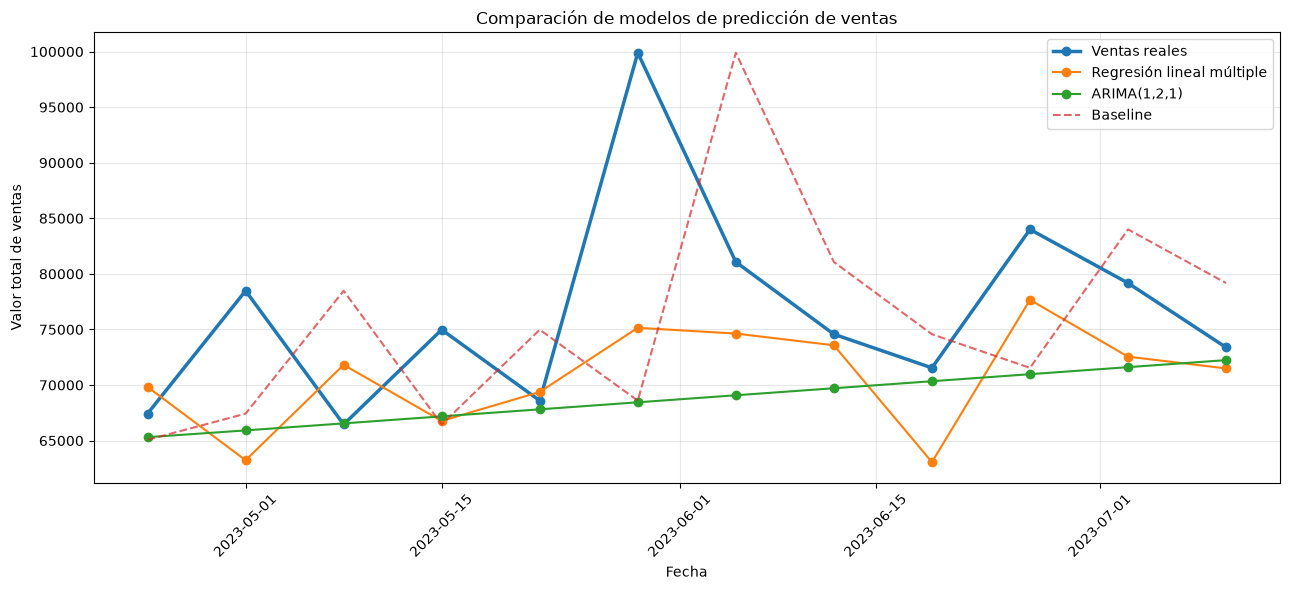

In [ ]:
# 15. COMPARACIÓN VISUAL DE MODELOS

comparacion_pred = pd.DataFrame({
    "Fecha": test_arima.index,
    "Real": test_arima.values,
    "Baseline": pred_baseline.values,
    "Regresion": pred_lr,
    "ARIMA": pred_arima.values
})

plt.figure(figsize=(13, 6))

plt.plot(
    comparacion_pred["Fecha"],
    comparacion_pred["Real"],
    marker="o",
    linewidth=2.5,
    label="Ventas reales"
)

plt.plot(
    comparacion_pred["Fecha"],
    comparacion_pred["Regresion"],
    marker="o",
    label="Regresión lineal múltiple"
)

plt.plot(
    comparacion_pred["Fecha"],
    comparacion_pred["ARIMA"],
    marker="o",
    label="ARIMA(1,2,1)"
)

plt.plot(
    comparacion_pred["Fecha"],
    comparacion_pred["Baseline"],
    linestyle="--",
    alpha=0.7,
    label="Baseline"
)

plt.title("Comparación de modelos de predicción de ventas")
plt.xlabel("Fecha")
plt.ylabel("Valor total de ventas")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> **Celda de diagnóstico:** se utiliza únicamente para localizar los DataFrames construidos durante el desarrollo del notebook. No forma parte del análisis sustantivo y puede omitirse en una versión de producción.


In [76]:
# Buscar DataFrames candidatos para el modelo

for nombre, obj in list(globals().items()):
    
    if isinstance(obj, pd.DataFrame):
        
        columnas = set(obj.columns)
        
        if {"FECHA", "Ventas"}.issubset(columnas):
            print(
                f"{nombre:30} "
                f"| shape: {obj.shape} "
                f"| columnas: {list(obj.columns)}"
            )

serie_ml                       | shape: (80, 11) | columnas: ['FECHA', 'Ventas', 'Unidades', 'Año', 'Mes', 'Semana', 'Tendencia', 'Lag_1', 'Lag_2', 'Lag_4', 'Media_4_sem']
_59                            | shape: (5, 3) | columnas: ['FECHA', 'Ventas', 'Unidades']
_60                            | shape: (10, 9) | columnas: ['FECHA', 'Ventas', 'Mes', 'Semana', 'Tendencia', 'Lag_1', 'Lag_2', 'Lag_4', 'Media_4_sem']
modelo_df                      | shape: (76, 11) | columnas: ['FECHA', 'Ventas', 'Unidades', 'Año', 'Mes', 'Semana', 'Tendencia', 'Lag_1', 'Lag_2', 'Lag_4', 'Media_4_sem']
_61                            | shape: (5, 9) | columnas: ['FECHA', 'Ventas', 'Mes', 'Semana', 'Tendencia', 'Lag_1', 'Lag_2', 'Lag_4', 'Media_4_sem']


## 10. Pronóstico futuro
Se generan 12 semanas futuras mediante pronóstico recursivo con la regresión ganadora. A partir de la segunda semana, los rezagos incorporan predicciones previas del propio modelo; por ello el horizonte debe interpretarse como una referencia estadística y no como una cifra determinística. El resultado se mantiene estable, principalmente alrededor de 135–150 mil por semana.


In [ ]:
# 16. PRONÓSTICO FUTURO CON REGRESIÓN LINEAL MÚLTIPLE

n_semanas = 12

# Histórico completo de ventas
historico = serie_ml[["FECHA", "Ventas"]].copy()
historico = historico.sort_values("FECHA").reset_index(drop=True)

# Última fecha observada
ultima_fecha = historico["FECHA"].max()

# Variables utilizadas por el modelo
features = [
    "Mes",
    "Semana",
    "Tendencia",
    "Lag_1",
    "Lag_2",
    "Lag_4",
    "Media_4_sem"
]

predicciones_futuras = []

# Ventas reales disponibles
ventas_hist = historico["Ventas"].tolist()

for i in range(1, n_semanas + 1):

    nueva_fecha = ultima_fecha + pd.Timedelta(weeks=i)

    # Crear variables para la nueva semana
    nueva_fila = pd.DataFrame({
        "Mes": [nueva_fecha.month],
        "Semana": [nueva_fecha.isocalendar().week],
        "Tendencia": [len(ventas_hist) + 1],
        "Lag_1": [ventas_hist[-1]],
        "Lag_2": [ventas_hist[-2]],
        "Lag_4": [ventas_hist[-4]],
        "Media_4_sem": [np.mean(ventas_hist[-4:])]
    })

    # Mantener el orden de variables
    nueva_fila = nueva_fila[features]

    # Predicción
    pred = modelo_lr.predict(nueva_fila)[0]

    # Guardamos la predicción
    predicciones_futuras.append(pred)

    # La predicción pasa a formar parte del histórico
    # para calcular los siguientes rezagos
    ventas_hist.append(pred)


# CREAR TABLA DE PRONÓSTICO

fechas_futuras = pd.date_range(
    start=ultima_fecha + pd.Timedelta(weeks=1),
    periods=n_semanas,
    freq="W-MON"
)

forecast_futuro = pd.DataFrame({
    "Fecha": fechas_futuras,
    "Venta_predicha": predicciones_futuras
})

forecast_futuro["Venta_predicha"] = (
    forecast_futuro["Venta_predicha"].round(2)
)

print("Última semana real:", ultima_fecha)
print("\nPronóstico próximas 12 semanas:")
display(forecast_futuro)

Última semana real: 2023-07-10 00:00:00

Pronóstico próximas 12 semanas:


,Fecha,Venta_predicha
0,2023-07-17,67105.53
1,2023-07-24,71508.27
2,2023-07-31,75090.69
3,2023-08-07,70381.04
4,2023-08-14,67519.54
5,2023-08-21,68609.38
6,2023-08-28,73066.25
7,2023-09-04,68085.96
8,2023-09-11,66967.82
9,2023-09-18,67511.30


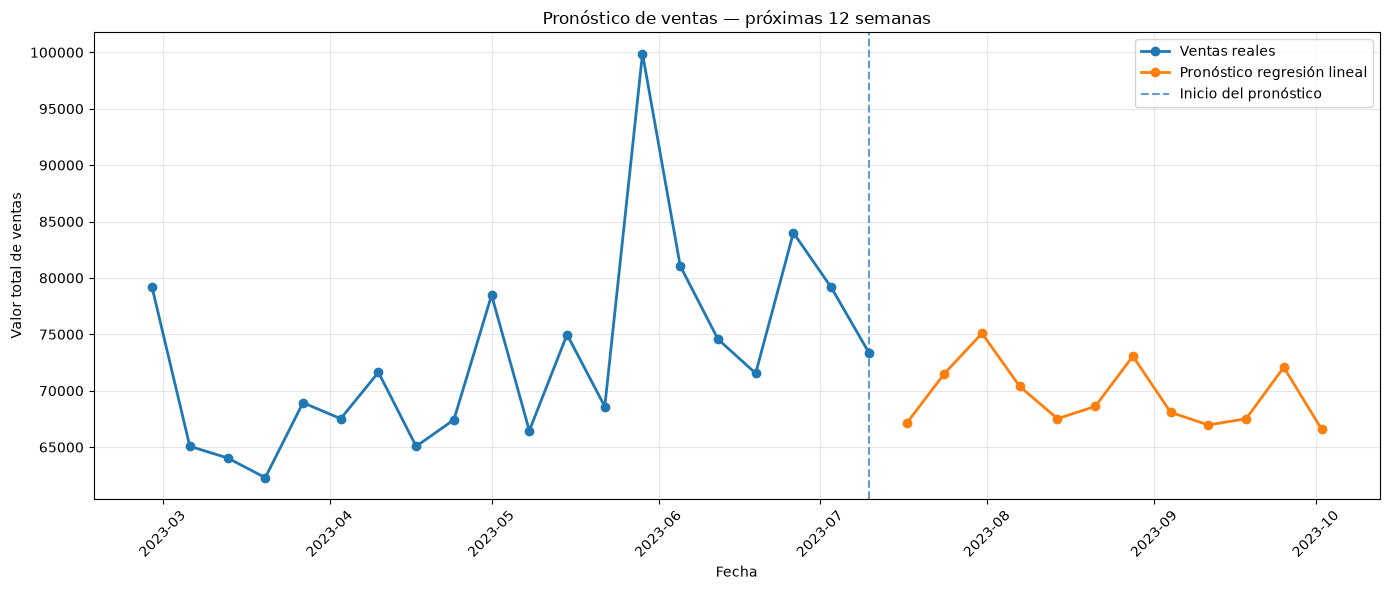

In [ ]:
# 17. VISUALIZACIÓN DEL PRONÓSTICO

plt.figure(figsize=(14, 6))

# Últimas 20 semanas reales
ultimas_20 = historico.tail(20)

plt.plot(
    ultimas_20["FECHA"],
    ultimas_20["Ventas"],
    marker="o",
    linewidth=2,
    label="Ventas reales"
)

# Pronóstico
plt.plot(
    forecast_futuro["Fecha"],
    forecast_futuro["Venta_predicha"],
    marker="o",
    linewidth=2,
    label="Pronóstico regresión lineal"
)

# Separación real / futuro
plt.axvline(
    ultima_fecha,
    linestyle="--",
    alpha=0.7,
    label="Inicio del pronóstico"
)

plt.title("Pronóstico de ventas — próximas 12 semanas")
plt.xlabel("Fecha")
plt.ylabel("Valor total de ventas")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Conclusiones metodológicas
- La integración produjo **122,002 registros** y no se detectaron duplicados exactos.
- **6.99%** de los registros de ventas no tuvo correspondencia de producto; esta limitación debe considerarse al analizar marca o SKU.
- Los valores extremos son frecuentes y se concentran en operaciones de alto volumen; se conservaron porque pueden representar actividad comercial real.
- En el periodo comparable Ene–Jun, las ventas crecieron **6.41%** en 2023 frente a 2022.
- La regresión lineal múltiple fue el modelo con mejor desempeño de prueba.
- El forecast futuro es estable, pero el histórico es corto y presenta volatilidad; una siguiente versión debería incorporar precio, promociones, inventario, distribución y otras variables explicativas.

### Recomendación
Usar el modelo como herramienta de apoyo para planeación y seguimiento, actualizándolo conforme se incorporen nuevas semanas y validando periódicamente si mantiene ventaja sobre el baseline.
